# Free wavepacket

The simplest test of a propagator: a Gaussian wavepacket without any potential.
Its width grows in time, while its momentum distribution stays the same.

We work in atomic units, $\hbar = m = 1$. The initial state is

$$\psi_0(x) = \frac{1}{\pi^{1/4}\sqrt{\sigma}}\,
\exp\!\left(-\frac{(x-x_0)^2}{2\sigma^2} + i p_0 (x - x_0)\right),$$

which has position uncertainty $\Delta x(0) = \sigma/\sqrt{2}$. The free Schrödinger equation gives

$$\langle x\rangle(t) = x_0 + p_0 t, \qquad
\Delta x(t) = \frac{\sigma}{\sqrt{2}}\sqrt{1 + \frac{t^2}{\sigma^4}}.$$

In [ ]:
# On Colab or JupyterLite (or anywhere without the package), install it first:
try:
    import so_schroedinger  # noqa: F401
except ImportError:
    import sys

    if sys.platform == "emscripten":  # JupyterLite: the package comes with the site
        %pip install so_schroedinger
    else:
        %pip install -q git+https://github.com/aeberspaecher/splitoperator

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["animation.embed_limit"] = 50  # MB
plt.rcParams["figure.dpi"] = 72

## Setting up grid, potential and wavepacket

The grid is periodic, as implied by the FFT. It has to be large enough that the packet does not
wrap around, and fine enough to resolve the largest momenta: $k_\mathrm{max} = \pi/\Delta x$.

In [2]:
sigma, x0, p0 = 1.0, -15.0, 3.0
psi0 = so.Gaussian1d(x0=x0, sigma=sigma, p0=p0)
grid = so.Grid1d(size=(-80.0, 80.0), grid_samples=2**12, potential=so.ConstantPotential(0.0), psi0=psi0)
prop = so.SplitOperator()

print(f"dx = {grid.dx:.4f}, k_max = {np.max(grid.k_vals):.1f}, norm = {grid.psi_norm:.6f}")

dx = 0.0391, k_max = 80.4, norm = 1.000000


## Comparing with the analytic solution

max. deviation of width: 8.348877145181177e-14
momentum stays at 3.0 ... 3.00000000000002


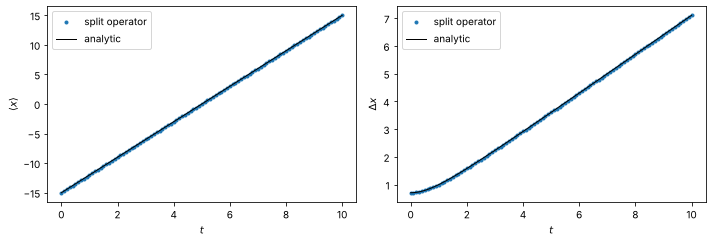

In [3]:
obs = so.analyzers.Observables()  # records <x>, <p>, width and norm each time it is called
obs(grid)
prop.propagate(grid, dt=0.01, n_steps=1000, callback=obs, every=10)
times, x_mean, x_width, p_mean = obs.t, obs.position, obs.width, obs.momentum

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(times, x_mean, "o", ms=3, label="split operator")
ax1.plot(times, x0 + p0 * times, "k-", lw=1, label="analytic")
ax1.set(xlabel="$t$", ylabel=r"$\langle x\rangle$")
ax1.legend()
ax2.plot(times, x_width, "o", ms=3, label="split operator")
ax2.plot(times, sigma / np.sqrt(2) * np.sqrt(1 + times**2 / sigma**4), "k-", lw=1, label="analytic")
ax2.set(xlabel="$t$", ylabel=r"$\Delta x$")
ax2.legend()
plt.tight_layout()

print("max. deviation of width:", np.max(np.abs(x_width - sigma / np.sqrt(2) * np.sqrt(1 + times**2 / sigma**4))))
print("momentum stays at", np.min(p_mean), "...", np.max(p_mean))

For a free particle the kinetic propagator $e^{-iT\Delta t}$ is applied exactly in momentum space
and $V = 0$, so the split operator method is exact up to round-off, independent of $\Delta t$.

## Animation

The real and imaginary parts show how the phase oscillates faster at the front of the packet:
the fast momentum components run ahead, the slow ones lag behind (a "chirp").

In [4]:
grid = so.Grid1d((-80.0, 80.0), 2**12, so.ConstantPotential(0.0), psi0)
fig, ax = plt.subplots(figsize=(8, 4.5))
anim = so.animate1d(grid, prop, dt=0.02, n_frames=60, steps_per_frame=5, show_re_im=True, ax=ax)
ax.set_xlim(-30, 20)
HTML(anim.to_jshtml())